In [6]:
import numpy as np
import math

# --- 1. SIMULATE AN IMAGE HISTOGRAM ---
# Creating a dummy histogram of a 256-level greyscale image with clear peaks
np.random.seed(42)
simulated_pixels = np.concatenate([
    np.random.normal(50, 15, 3000),   # Background peak
    np.random.normal(130, 20, 4000),  # Midtone object peak
    np.random.normal(210, 15, 3000)   # Highlight peak
])
simulated_pixels = np.clip(simulated_pixels, 0, 255).astype(np.uint8)

# Compute normalized histogram probabilities
counts, bins = np.histogram(simulated_pixels, bins=256, range=(0, 256))
prob_histogram = counts / len(simulated_pixels)

# --- 2. OTSU'S OBJECTIVE FUNCTION ---
def evaluate_otsu_fitness(thresholds):
    """
    Computes Otsu's Between-Class Variance for K thresholds.
    Maximizing this function yields cleaner segmented boundaries.
    """
    # Sort thresholds to create chronological class partitions
    t = np.sort(np.round(thresholds).astype(int))
    t = np.clip(t, 1, 254)

    # Define class boundaries spanning from 0 to 255
    boundaries = [0] + list(t) + [255]

    between_class_variance = 0.0
    global_mean = np.sum(np.arange(256) * prob_histogram)

    for i in range(len(boundaries) - 1):
        low, high = boundaries[i], boundaries[i+1]

        # Calculate class probability weight (w)
        w = np.sum(prob_histogram[low:high])
        if w == 0:
            continue

        # Calculate class mean intensity (mu)
        mean_intensity = np.sum(np.arange(low, high) * prob_histogram[low:high]) / w

        # Accumulate structural variance
        between_class_variance += w * (mean_intensity - global_mean) ** 2

    # We return the negative because Cuckoo Search minimizes the fitness value
    return -between_class_variance

# --- 3. CUCKOO SEARCH OPTIMIZATION MECHANISM WITH PROGRESS TRACKING ---
def cuckoo_search_thresholding(n_nests=15, max_iter=50, pa=0.25, k_thresholds=2):
    lb, ub = 1.0, 254.0

    # Initialize random nest layouts representing threshold markers
    nests = lb + (ub - lb) * np.random.rand(n_nests, k_thresholds)
    fitness = np.array([evaluate_otsu_fitness(nest) for nest in nests])

    best_idx = np.argmin(fitness)
    best_nest = nests[best_idx].copy()
    best_fitness = fitness[best_idx]

    # Levy Flight scale factors (Mantegna distribution implementation)
    beta = 1.5
    sigma = (math.gamma(1+beta)*np.sin(np.pi*beta/2) / (math.gamma((1+beta)/2)*beta*2**((beta-1)/2)))**(1/beta)

    print("--- Optimization Progress ---")
    for iteration in range(1, max_iter + 1):
        for i in range(n_nests):
            u = np.random.normal(0, sigma, size=k_thresholds)
            v = np.random.normal(0, 1, size=k_thresholds)
            step = u / (np.abs(v) ** (1 / beta))

            # Update nest layout through heavy-tailed Levy step sizes
            new_nest = nests[i] + 0.05 * step * (nests[i] - best_nest)
            new_nest = np.clip(new_nest, lb, ub)

            new_fit = evaluate_otsu_fitness(new_nest)

            # Simple replacement step
            random_idx = np.random.randint(0, n_nests)
            if new_fit < fitness[random_idx]:
                nests[random_idx] = new_nest
                fitness[random_idx] = new_fit

        # Discovery mechanism: Abandon the worst performing solutions
        abandon_indices = np.argsort(fitness)[-int(pa * n_nests):]
        for idx in abandon_indices:
            nests[idx] = lb + (ub - lb) * np.random.rand(k_thresholds)
            fitness[idx] = evaluate_otsu_fitness(nests[idx])

        # Global target updates
        current_best_idx = np.argmin(fitness)
        if fitness[current_best_idx] < best_fitness:
            best_fitness = fitness[current_best_idx]
            best_nest = nests[current_best_idx].copy()

        # Log progress at milestone iterations
        if iteration in [10, 30, 50]:
            temp_thresholds = np.sort(np.round(best_nest).astype(int))
            print(f"Iteration {iteration:02d}: Best Thresholds = {temp_thresholds}, Best Otsu Variance = {-best_fitness:.4f}")

    print("-----------------------------\n")
    return np.sort(np.round(best_nest).astype(int)), -best_fitness

# Execute the image segmentation optimizer
optimal_thresholds, max_variance = cuckoo_search_thresholding()

print("--- Image Processing Optimization Complete ---")
print(f"Optimal Multilevel Thresholds Found: T1 = {optimal_thresholds[0]}, T2 = {optimal_thresholds[1]}")
print(f"Maximized Between-Class Otsu Variance: {max_variance:.4f}")

--- Optimization Progress ---
Iteration 10: Best Thresholds = [ 88 165], Best Otsu Variance = 3843.6973
Iteration 30: Best Thresholds = [ 88 165], Best Otsu Variance = 3843.6973
Iteration 50: Best Thresholds = [ 88 165], Best Otsu Variance = 3843.6973
-----------------------------

--- Image Processing Optimization Complete ---
Optimal Multilevel Thresholds Found: T1 = 88, T2 = 165
Maximized Between-Class Otsu Variance: 3843.6973


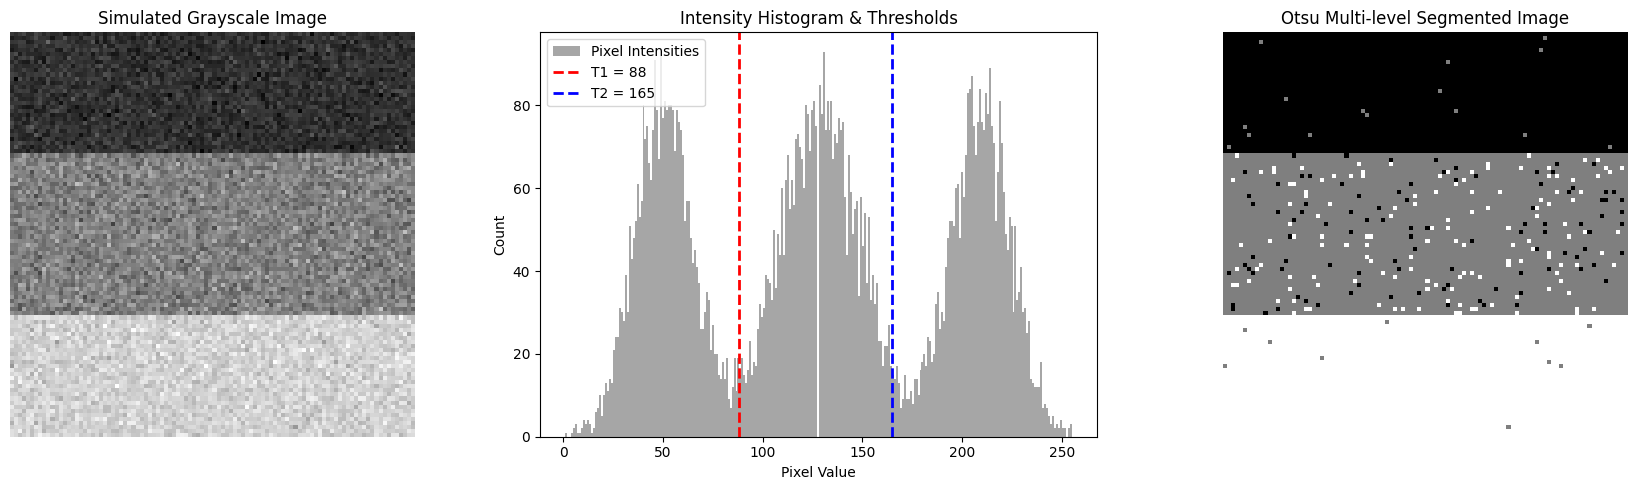

In [3]:
import matplotlib.pyplot as plt

# Reconstruct a 2D representation of the simulated pixel data (e.g., a 100x100 grid)
# Since it's synthetic 1D data of 10,000 pixels, we can reshape it to 100x100 to visualize it as an image
spatial_image = simulated_pixels.reshape((100, 100))

# Create a segmented version of the image using the optimal thresholds
segmented_image = np.zeros_like(spatial_image)
# Region 1 (0 to T1)
segmented_image[spatial_image <= optimal_thresholds[0]] = 0
# Region 2 (T1+1 to T2)
segmented_image[(spatial_image > optimal_thresholds[0]) & (spatial_image <= optimal_thresholds[1])] = 127
# Region 3 (T2+1 to 255)
segmented_image[spatial_image > optimal_thresholds[1]] = 255

# --- Plotting the Results ---
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# 1. Show the synthesized 2D grayscale image
axes[0].imshow(spatial_image, cmap='gray')
axes[0].set_title("Simulated Grayscale Image")
axes[0].axis('off')

# 2. Show the histogram with threshold divisions
axes[1].hist(simulated_pixels, bins=256, color='gray', alpha=0.7, label='Pixel Intensities')
axes[1].axvline(optimal_thresholds[0], color='r', linestyle='--', linewidth=2, label=f'T1 = {optimal_thresholds[0]}')
axes[1].axvline(optimal_thresholds[1], color='b', linestyle='--', linewidth=2, label=f'T2 = {optimal_thresholds[1]}')
axes[1].set_title("Intensity Histogram & Thresholds")
axes[1].set_xlabel("Pixel Value")
axes[1].set_ylabel("Count")
axes[1].legend()

# 3. Show the segmented 2D image mapped to 3 distinct regions
axes[2].imshow(segmented_image, cmap='gray')
axes[2].set_title("Otsu Multi-level Segmented Image")
axes[2].axis('off')

plt.tight_layout()
plt.show()

In [4]:
print("=== Cuckoo Search Otsu Thresholding Results ===")
print(f"Optimal Threshold 1 (T1)       : {optimal_thresholds[0]}")
print(f"Optimal Threshold 2 (T2)       : {optimal_thresholds[1]}")
print(f"Maximized Between-Class Variance: {max_variance:.4f}")
print("------------------------------------------------")
print(f"Region 1 (Background)          : [0, {optimal_thresholds[0]}]")
print(f"Region 2 (Midtones)            : [{optimal_thresholds[0] + 1}, {optimal_thresholds[1]}]")
print(f"Region 3 (Highlights)          : [{optimal_thresholds[1] + 1}, 255]")

=== Cuckoo Search Otsu Thresholding Results ===
Optimal Threshold 1 (T1)       : 88
Optimal Threshold 2 (T2)       : 165
Maximized Between-Class Variance: 3843.6973
------------------------------------------------
Region 1 (Background)          : [0, 88]
Region 2 (Midtones)            : [89, 165]
Region 3 (Highlights)          : [166, 255]
